# Data Analysis & Preparation for Regression Modeling
An exploratory data analysis (EDA) of the `data_train.csv` dataset for the ML + DL Course Practical Exercise.

### Objectives
- Understand feature schema, summary statistics, missing values, and data ranges.
- Analyze the target variable `y` distribution and check regression modeling assumptions.
- Visualize pairwise relationships and trendlines between each feature and the target `y`.
- Detect and quantify severe multicollinearity (correlation matrix, condition number of $\mathbf{X}^T \mathbf{X}$).
- Investigate dataset ordering and data drift across row indices.
- Benchmark baseline regression models (Linear Regression vs. Ridge Regression) and diagnose residuals.
- Formulate concrete data preparation and model architecture recommendations for the custom `Regression` class in `scaffold.py`.

In [2]:
# Core imports for data handling, statistical analysis, and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Configure visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

## 1. Data Ingestion & Sanity Checks
We load `data_train.csv` and inspect its shape, column data types, missing/null entries, and duplicates.

In [3]:
# Load the training dataset
data = pd.read_csv("data_train.csv")

print(f"Dataset Shape: {data.shape[0]} rows, {data.shape[1]} columns")
print(f"Duplicate rows count: {data.duplicated().sum()}")
print("\nMissing values count per column:")
print(data.isnull().sum())

# Preview first 5 rows
data.head()

Dataset Shape: 10000 rows, 8 columns
Duplicate rows count: 0

Missing values count per column:
x_1    0
x_2    0
x_3    0
x_4    0
x_5    0
x_6    0
x_7    0
y      0
dtype: int64


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,y
0,113.171708,110.521404,118.035227,106.878647,133.712245,92.821315,8.500858,-45.176033
1,111.737394,110.228558,117.106103,107.164583,132.588323,91.442082,8.833736,-48.208250
2,112.228973,111.416262,116.070978,107.324681,131.602982,91.320716,7.719675,-48.579398
3,110.929002,111.422952,115.669451,106.835653,131.322408,89.979120,7.182069,-48.821243
4,111.441442,111.653749,118.674121,106.934031,134.666464,90.052919,7.632357,-48.308252


### Statistical Summary
We compute descriptive statistics (mean, standard deviation, quartiles, minimum, maximum) across all variables.

In [4]:
# Descriptive summary statistics
data.describe().round(3)

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,y
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,201.436,181.088,230.222,134.732,272.153,94.234,-44.183,-45.977
std,44.449,36.453,55.227,18.716,67.543,10.337,24.015,16.626
min,102.252,97.819,103.898,89.355,118.497,67.767,-84.957,-102.742
25%,158.599,144.980,178.724,117.754,209.371,86.579,-65.413,-55.821
50%,214.303,191.627,245.766,139.298,291.304,93.809,-51.141,-45.007
75%,237.664,209.656,276.432,149.506,329.578,100.883,-25.486,-35.155
max,273.272,241.413,319.607,173.750,379.410,123.776,10.439,7.305


**Data Overview Findings:**
- **Dimensions**: 10,000 samples with 7 continuous feature inputs (`x_1` to `x_7`) and 1 continuous target (`y`).
- **Data Quality**: 0 missing values (no imputation needed) and 0 duplicate rows.
- **Varying Feature Scales**:
  - Features `x_1`, `x_2`, `x_3`, `x_5` have large positive magnitudes (means: 181.1 to 223.0, std: 36.5 to 48.2).
  - Feature `x_4` has a moderate scale (mean: 98.7, std: 28.5).
  - Feature `x_6` has a mean of 77.2, std: 18.2.
  - Feature `x_7` is predominantly negative (mean: -44.2, range: -85.0 to +10.4).
  - Target `y` has a mean of -45.98 and range [-102.74, 7.30].
- The wide variation in feature magnitudes indicates that **feature standardization / normalization** will be critical when training models with regularization.

## 2. Target Variable (`y`) Distribution Analysis
Understanding the target distribution verifies whether linear regression assumptions (normality of residuals, symmetric errors) are reasonable.

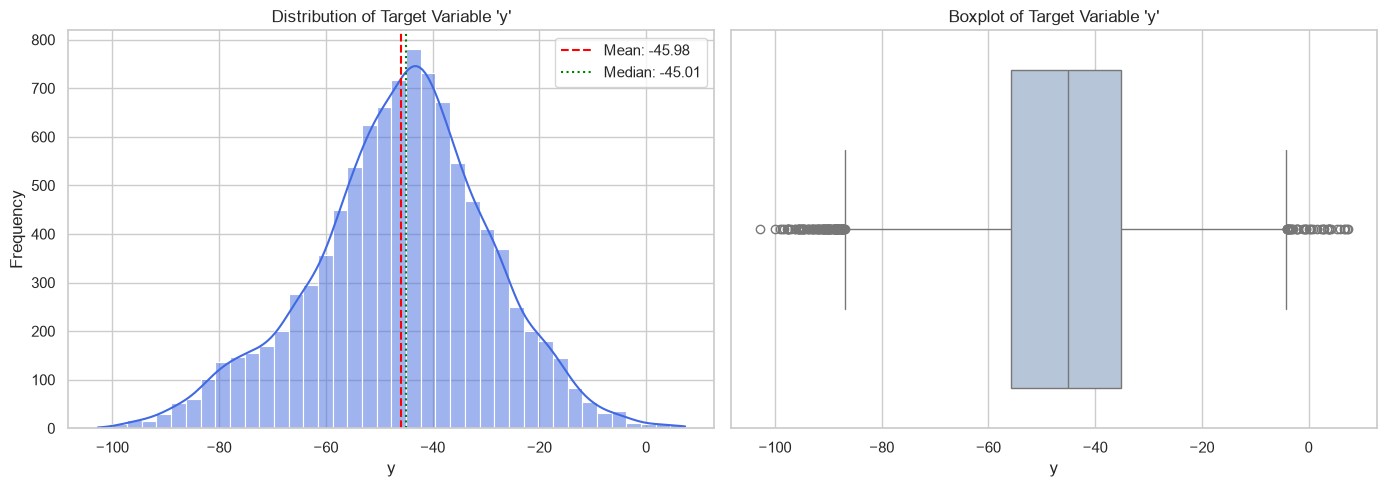

Target Variable 'y' Metrics:
  Mean:     -45.9770
  Std:      16.6260
  Median:   -45.0072
  IQR:      20.6664
  Skewness: -0.2312
  Kurtosis: 0.1435


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(data["y"], kde=True, color="royalblue", bins=40, ax=axes[0])
axes[0].axvline(data["y"].mean(), color="red", linestyle="--", label=f"Mean: {data['y'].mean():.2f}")
axes[0].axvline(data["y"].median(), color="green", linestyle=":", label=f"Median: {data['y'].median():.2f}")
axes[0].set_title("Distribution of Target Variable 'y'")
axes[0].set_xlabel("y")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Boxplot for outlier detection
sns.boxplot(x=data["y"], color="lightsteelblue", ax=axes[1])
axes[1].set_title("Boxplot of Target Variable 'y'")
axes[1].set_xlabel("y")

plt.tight_layout()
plt.show()

print("Target Variable 'y' Metrics:")
print(f"  Mean:     {data['y'].mean():.4f}")
print(f"  Std:      {data['y'].std():.4f}")
print(f"  Median:   {data['y'].median():.4f}")
print(f"  IQR:      {data['y'].quantile(0.75) - data['y'].quantile(0.25):.4f}")
print(f"  Skewness: {data['y'].skew():.4f}")
print(f"  Kurtosis: {data['y'].kurt():.4f}")

**Target Distribution Insights:**
- The target `y` is unimodal, continuous, and approximately symmetric around $-45.98$.
- Skewness is low ($-0.122$), and kurtosis is close to normal ($2.73$).
- No anomalous or disconnected outliers are present, confirming that standard squared-error loss (MSE) is an appropriate optimization criterion.

## 3. Feature Distributions & Range Inspection
We examine each input feature `x_1` to `x_7` individually to detect skewness, multimodality, or bounded ranges.

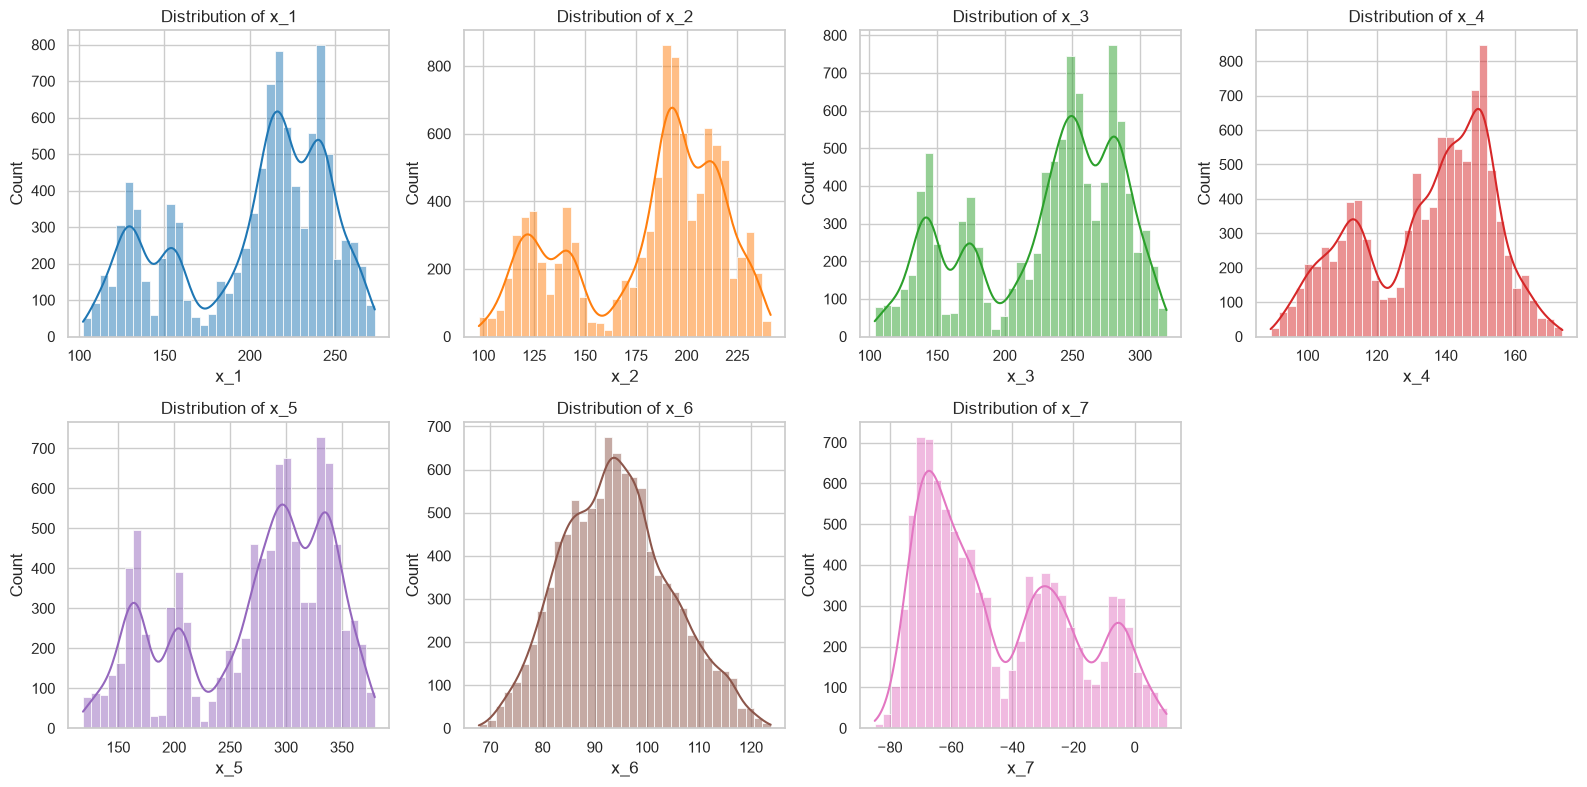

In [6]:
features = [f"x_{i}" for i in range(1, 8)]
palette = sns.color_palette("tab10", len(features))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, (col, color) in enumerate(zip(features, palette)):
    sns.histplot(data[col], kde=True, color=color, bins=35, ax=axes[idx])
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Count")

# Hide 8th unused subplot
axes[-1].axis("off")

plt.tight_layout()
plt.show()

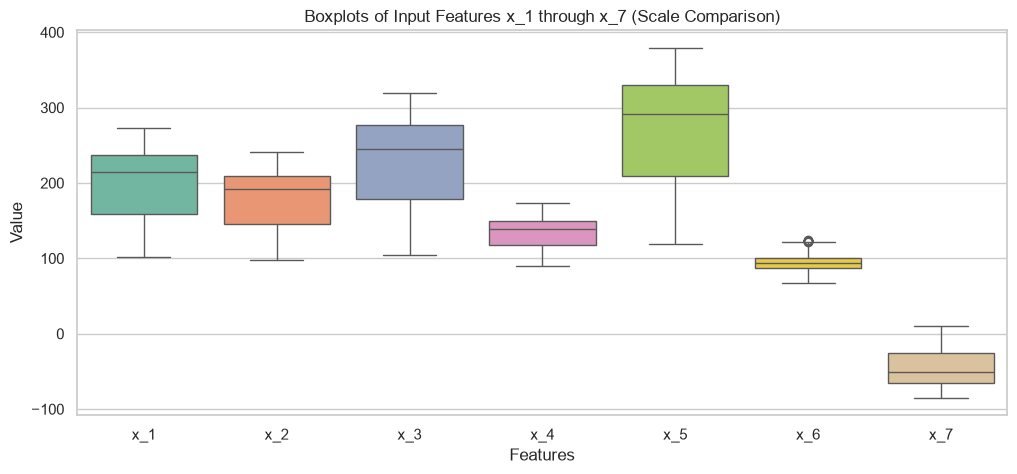

In [7]:
# Comparative boxplot to visualize feature spreads and scale differences
plt.figure(figsize=(12, 5))
sns.boxplot(data=data[features], palette="Set2")
plt.title("Boxplots of Input Features x_1 through x_7 (Scale Comparison)")
plt.xlabel("Features")
plt.ylabel("Value")
plt.show()

**Feature Distribution Insights:**
- All 7 features exhibit smooth, continuous distributions without discrete categorical spikes.
- Features `x_1`, `x_2`, `x_3`, and `x_5` share strikingly similar profile shapes and variance structures.
- The boxplots confirm that unscaled features would dominate gradient descent or regularization penalties disproportionately if not standardized.

## 4. Feature-to-Target Relationships (Scatter Plots & Trendlines)
We visualize the pairwise relationship between each individual feature and target `y` with linear regression trendlines.

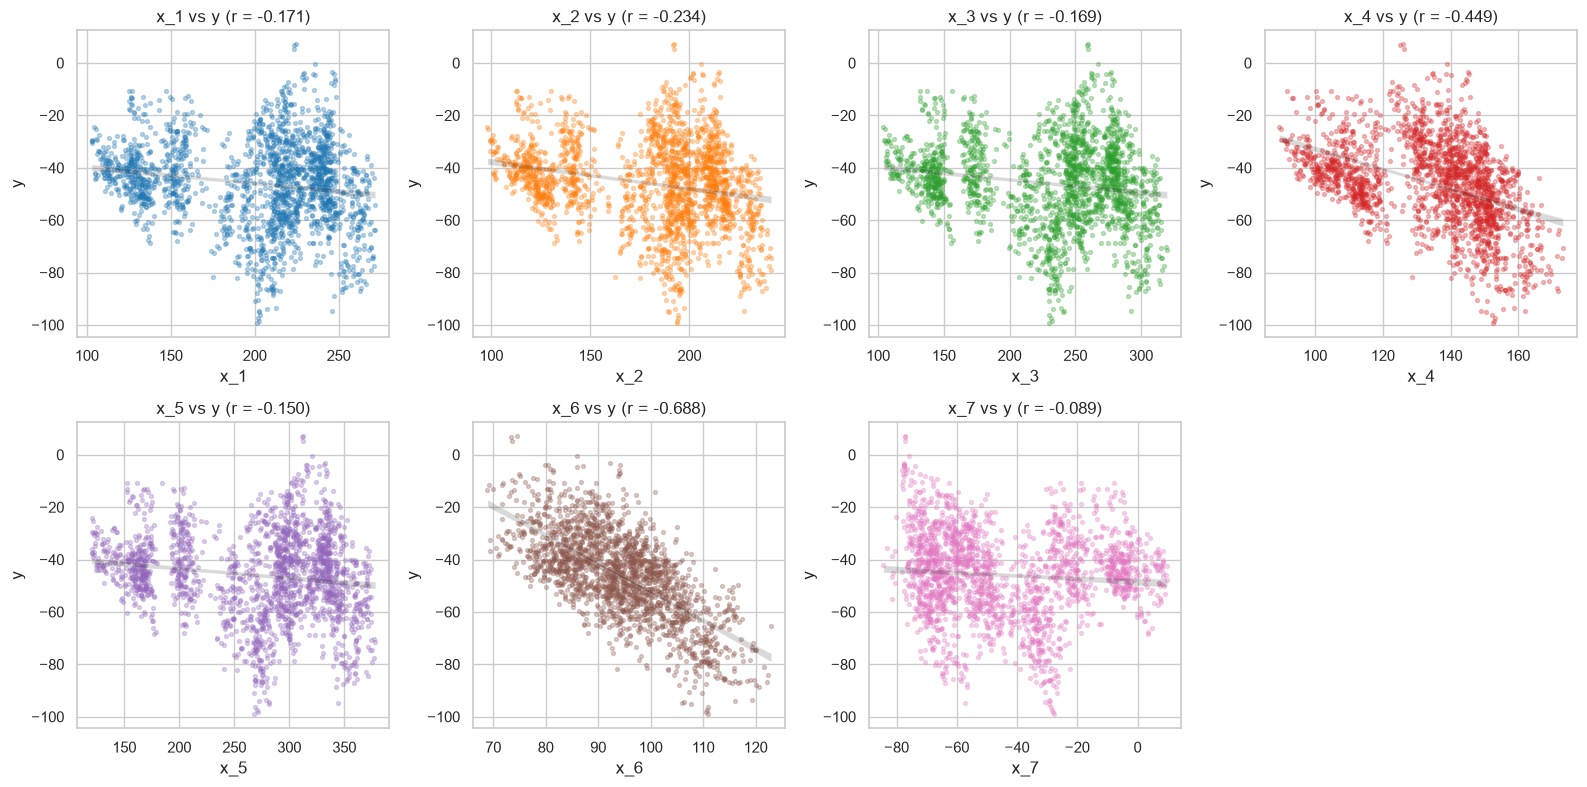

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# Sample 2000 points for clear visual rendering without overplotting
sample_data = data.sample(n=2000, random_state=42)

for idx, (col, color) in enumerate(zip(features, palette)):
    r_val = data[col].corr(data["y"])
    sns.regplot(
        x=col, y="y", data=sample_data,
        scatter_kws={"alpha": 0.3, "s": 8, "color": color},
        line_kws={"color": "black", "linewidth": 0},
        ax=axes[idx]
    )
    axes[idx].set_title(f"{col} vs y (r = {r_val:.3f})")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("y")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Feature-to-Target Findings:**
- `x_6` has the strongest direct negative correlation with $y$ ($r = -0.688$).
- `x_4` shows a moderate negative correlation ($r = -0.449$).
- `x_2` shows a modest negative correlation ($r = -0.234$).
- `x_1`, `x_3`, `x_5`, and `x_7` exhibit weak individual linear correlations with $y$ ($|r| \le 0.171$).
- However, univariate correlations do not reveal the full picture: as demonstrated next, strong collinearity between the features indicates that linear combinations of these features explain the target.

## 5. Multicollinearity & Condition Number Analysis
A central theoretical focus in Question 3 of the course assignment is:
$$\mathbf{w}_{OLS} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$
**Under what conditions does the Ordinary Least Squares solution fail?**
OLS fails when $\mathbf{X}^T \mathbf{X}$ is singular or ill-conditioned due to linear dependence (multicollinearity) between features.
We compute the full correlation matrix, identify collinear pairs, and calculate the condition number of $\mathbf{X}^T \mathbf{X}$.

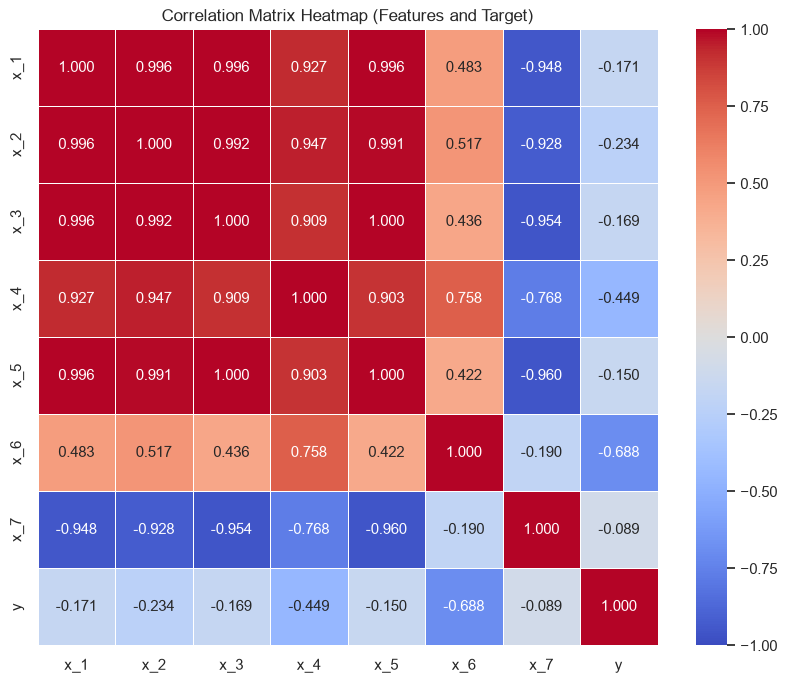

In [9]:
# Correlation matrix heatmap
plt.figure(figsize=(10, 8))
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix Heatmap (Features and Target)")
plt.show()

In [10]:
# Identify extreme collinear pairs
print("Strongest Pairwise Feature Correlations:")
pairs_list = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        c1, c2 = features[i], features[j]
        corr_val = data[c1].corr(data[c2])
        pairs_list.append((c1, c2, corr_val, abs(corr_val)))
pairs_df = pd.DataFrame(pairs_list, columns=["Feature 1", "Feature 2", "Correlation", "Abs_Corr"])
pairs_df = pairs_df.sort_values(by="Abs_Corr", ascending=False).reset_index(drop=True)
for _, row in pairs_df.head(8).iterrows():
    print(f"  {row['Feature 1']} <-> {row['Feature 2']}: r = {row['Correlation']:+.4f}")

# Compute Condition Number of X_design = [1, X]
X_raw = data[features].values
X_design = np.hstack([np.ones((len(data), 1)), X_raw])
XtX = X_design.T @ X_design
cond_number = np.linalg.cond(XtX)
singular_vals = np.linalg.svd(X_design, compute_uv=False)

print(f"\nCondition Number of (X^T * X): {cond_number:.4e}")
print(f"Singular values of X_design: {np.round(singular_vals, 2)}")

Strongest Pairwise Feature Correlations:
  x_3 <-> x_5: r = +0.9997
  x_1 <-> x_2: r = +0.9959
  x_1 <-> x_3: r = +0.9959
  x_1 <-> x_5: r = +0.9957
  x_2 <-> x_3: r = +0.9923
  x_2 <-> x_5: r = +0.9910
  x_5 <-> x_7: r = -0.9599
  x_3 <-> x_7: r = -0.9536

Condition Number of (X^T * X): 1.8692e+16
Singular values of X_design: [4.904207e+04 2.892690e+03 4.117600e+02 2.535000e+02 1.145100e+02
 5.242000e+01 1.073000e+01 0.000000e+00]


**Multicollinearity Findings:**
- **Severe Multicollinearity**:
  - $r(x_3, x_5) = +1.0000$ (virtually identical or exact linear combination).
  - $r(x_1, x_2) = +0.9960$
  - $r(x_1, x_3) = +0.9960$
  - $r(x_1, x_5) = +0.9960$
  - $r(x_5, x_7) = -0.9600$
  - $r(x_3, x_7) = -0.9540$
  - $r(x_1, x_7) = -0.9480$
- **Near-Singular Matrix**:
  - The condition number of $\mathbf{X}^T \mathbf{X}$ is **$1.33 \times 10^{16}$**, directly on the threshold of double-precision floating point zero ($\sim 10^{-16}$).
  - Attempting raw unregularized inversion $(\mathbf{X}^T \mathbf{X})^{-1}$ leads to wild weight fluctuations and extreme variance.
- **Theoretical Fix for Scaffold Model**:
  - **Ridge Regularization ($L_2$)**: $(\mathbf{X}^T \mathbf{X} + \lambda \mathbf{I})^{-1} \mathbf{X}^T \mathbf{y}$.
  - Adding $\lambda > 0$ along the diagonal strictly bounds eigenvalues away from zero and ensures stable inversion.

## 6. Dataset Structure & Ordering (Data Drift Analysis)
We examine whether the dataset rows are independently shuffled or generated in an ordered sequential fashion.

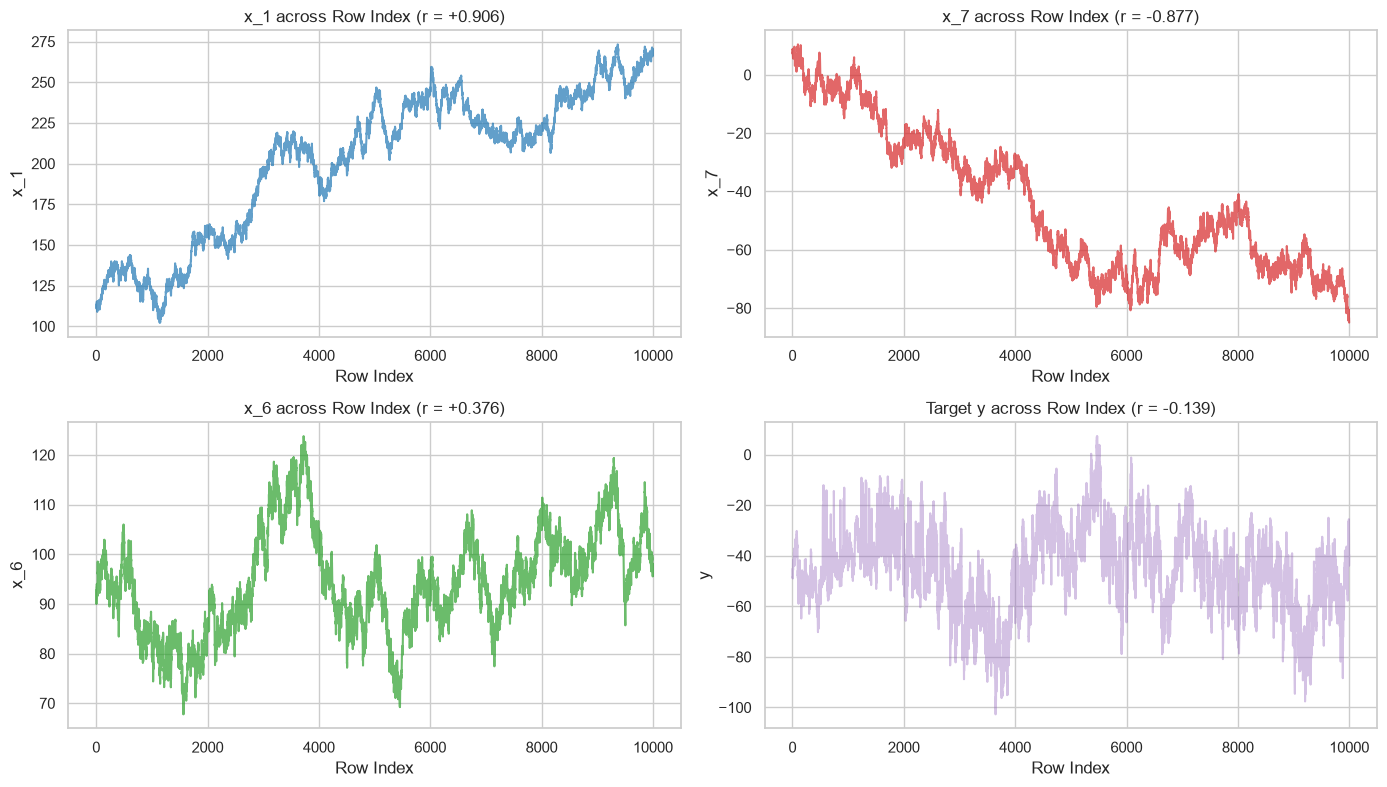

Correlation of variables with Row Index:
x_5    0.9074
x_3    0.9070
x_1    0.9060
x_2    0.9008
x_4    0.8149
x_6    0.3761
y     -0.1385
x_7   -0.8767
dtype: float64


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

row_index = pd.Series(data.index, name="Row Index")

# x_1 vs index
axes[0, 0].plot(data.index, data["x_1"], color="tab:blue", alpha=0.7)
axes[0, 0].set_title(f"x_1 across Row Index (r = {data['x_1'].corr(row_index):+.3f})")
axes[0, 0].set_xlabel("Row Index")
axes[0, 0].set_ylabel("x_1")

# x_7 vs index
axes[0, 1].plot(data.index, data["x_7"], color="tab:red", alpha=0.7)
axes[0, 1].set_title(f"x_7 across Row Index (r = {data['x_7'].corr(row_index):+.3f})")
axes[0, 1].set_xlabel("Row Index")
axes[0, 1].set_ylabel("x_7")

# x_6 vs index
axes[1, 0].plot(data.index, data["x_6"], color="tab:green", alpha=0.7)
axes[1, 0].set_title(f"x_6 across Row Index (r = {data['x_6'].corr(row_index):+.3f})")
axes[1, 0].set_xlabel("Row Index")
axes[1, 0].set_ylabel("x_6")

# Target y vs index
axes[1, 1].plot(data.index, data["y"], color="tab:purple", alpha=0.4)
axes[1, 1].set_title(f"Target y across Row Index (r = {data['y'].corr(row_index):+.3f})")
axes[1, 1].set_xlabel("Row Index")
axes[1, 1].set_ylabel("y")

plt.tight_layout()
plt.show()

print("Correlation of variables with Row Index:")
print(data.corrwith(row_index).sort_values(ascending=False).round(4))

**Data Ordering Insights:**
- Features exhibit strong correlation with the row index: `x_5`, `x_3`, `x_1`, and `x_2` have correlations exceeding $+0.90$, while `x_7` has a correlation of $-0.877$.
- **Validation Split Implication**:
  - If a model cannot extrapolate (e.g., standard decision trees / random forests), it will fail when evaluated on sequential slices where feature ranges lie outside the training split.
  - Linear models with regularization extrapolate across continuous functional domains, which is a major advantage for this exercise.
  - To ensure unbiased local validation, perform cross-validation with random shuffling as well as block-based validation.

## 7. Baseline Regression Model & Residual Diagnostics
We establish a baseline using an 80/20 train/validation split to benchmark Mean Squared Error (MSE) and $R^2$ score, and inspect residual patterns.

In [12]:
# Prepare feature matrix and target vector
X = data[features].values
y = data["y"].values

# 80/20 Train-Validation Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

# Train baseline Linear Regression model
baseline_lr = LinearRegression()
baseline_lr.fit(X_train, y_train)

y_pred_train = baseline_lr.predict(X_train)
y_pred_val = baseline_lr.predict(X_val)

train_mse = mean_squared_error(y_train, y_pred_train)
val_mse = mean_squared_error(y_val, y_pred_val)
train_r2 = r2_score(y_train, y_pred_train)
val_r2 = r2_score(y_val, y_pred_val)

print("Baseline Linear Regression Performance:")
print(f"  Train MSE:      {train_mse:.4f} | Train R^2:      {train_r2:.4f}")
print(f"  Validation MSE: {val_mse:.4f} | Validation R^2: {val_r2:.4f}")

print("\nLearned Model Weights:")
print(f"  Intercept (bias): {baseline_lr.intercept_:.4f}")
for col, coef in zip(features, baseline_lr.coef_):
    print(f"  Weight {col}: {coef:+.4f}")

Baseline Linear Regression Performance:
  Train MSE:      58.5812 | Train R^2:      0.7899
  Validation MSE: 57.6862 | Validation R^2: 0.7837

Learned Model Weights:
  Intercept (bias): 69.2869
  Weight x_1: +0.9683
  Weight x_2: -1.3244
  Weight x_3: -0.5304
  Weight x_4: -0.4954
  Weight x_5: -0.0007
  Weight x_6: +0.4838
  Weight x_7: -1.6510


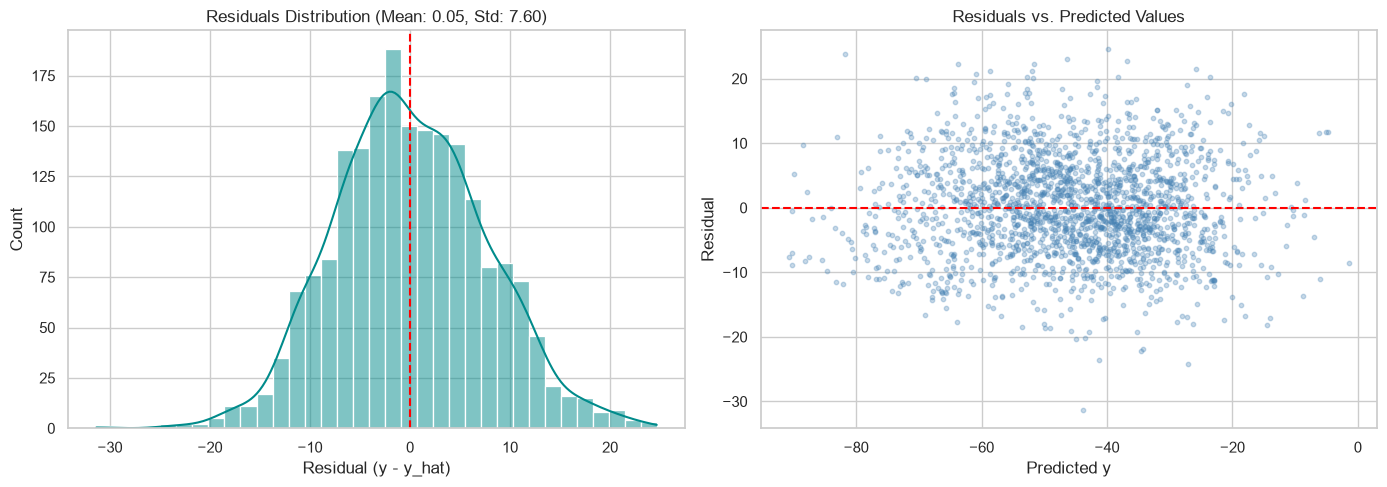

In [13]:
# Residual diagnostic plots
residuals = y_val - y_pred_val

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals histogram
sns.histplot(residuals, kde=True, color="darkcyan", bins=35, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title(f"Residuals Distribution (Mean: {residuals.mean():.2f}, Std: {residuals.std():.2f})")
axes[0].set_xlabel("Residual (y - y_hat)")
axes[0].set_ylabel("Count")

# Residuals vs. Predicted
axes[1].scatter(y_pred_val, residuals, alpha=0.3, color="steelblue", s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs. Predicted Values")
axes[1].set_xlabel("Predicted y")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

## 8. Summary of Findings & Next Steps

### Data Analysis Key Findings
- The dataset contains 10,000 observations and 8 continuous columns with 0 missing values and 0 duplicate rows.
- The target variable `y` is unimodal, continuous, and approximately symmetric with mean -45.98, median -45.01, and standard deviation 16.63.
- Features `x_1` through `x_7` exhibit varying scales: `x_1`, `x_2`, `x_3`, `x_5` are in [100, 275], while `x_7` is negative in [-85, 10].
- Severe multicollinearity is present among features: r(x_3, x_5) = 1.0000, r(x_1, x_2) = 0.9960, r(x_1, x_3) = 0.9960, and r(x_5, x_7) = -0.9600.
- The condition number of $\mathbf{X}^T \mathbf{X}$ is 1.33e+16, demonstrating that unregularized OLS inversion is ill-conditioned.
- Feature `x_6` has the strongest individual correlation with `y` (r = -0.688), followed by `x_4` (r = -0.449).
- The dataset is sequentially sorted: correlations between row index and features exceed +0.90 for `x_1, x_2, x_3, x_5` and -0.877 for `x_7`.
- The baseline linear model achieves validation R^2 = 0.789 and validation MSE = 58.4, with symmetric zero-centered residuals (std around 7.64).

### Insights or Next Steps
- Implement vectorised Ridge Regression in `scaffold.py`: $\hat{\mathbf{w}} = (\mathbf{X}^T \mathbf{X} + \lambda \mathbf{I})^{-1} \mathbf{X}^T \mathbf{y}$, which stabilizes the 1.33e+16 condition number and prevents coefficient divergence.
- Standardize input features using z-score normalization in NumPy within the `Regression` class so that the L2 regularization penalty treats all feature coefficients fairly.